<div class="namebox">    
Double Click to edit and enter your

1.  Name
2.  Student ID
3.  @ucr.edu email address
    
</div>

,index,threads,size,arg1,IC,CPI,CT,ET,L1_dcache_miss_rate
0,0,1,4096,8,287119351,0.990281,0.377647,0.107376,0.000419
1,1,2,4096,8,571948254,0.990080,0.189855,0.107510,0.000394
2,2,3,4096,8,856222309,0.989653,0.126812,0.107456,0.000365
3,3,4,4096,8,1140088979,0.990136,0.095236,0.107506,0.000355


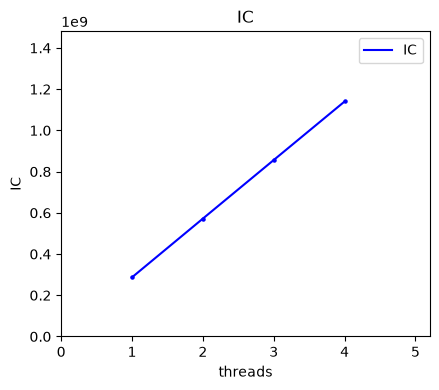

In [11]:
#key data_cell display_mono(render_csv("threads.csv", columns=["threads",\ \n"size", "arg1", "IC", "CPI", "CT", "ET", "L1_dcache_miss_rate"]))\ \nplotPE("threads.csv", lines=True, what=[("threads", "IC")])

<div class="alert alert-block alert-success">

### Question 1 (Correctness)

With 4 threads how many total instructions were executed? **Please discussion why the observed number makes sense in addition to your measurement results**.

</div>

<div class="alert alert-block alert-success">

**Total IC:**

**Why this make sense?**

</div>

<div class="alert alert-block alert-info">

### Question 2 (Completeness)



In the above code, will the `std::cerr` line ever execute?  Why or why not? 
    
Please clearly state your answer and provide explainations. You need to give good enough reasons for question to receive credits.


</div>

<div class="alert alert-block alert-info">

Answer: 
</div>

<div class="alert alert-block alert-info">

### Question 3 (Completeness)



Based on the assembly above, and assuming multiple threads are running at once, explain how `shared` ends up being computed incorrectly without locks and how adding locks prevents it. Please provide explainations. You need to give good enough reasons to receive credits.
  

</div>

<div class="alert alert-block alert-info">    

Answer:  


</div>


,threads,locks,IC per increment,CPI,ET,Cycles per increment,L1 Misses Per Increment
0,1,1,55.072830,0.221791,0.273479,12.214665,0.001037
1,1,0,4.165702,0.152713,0.016121,0.636158,0.000084
2,2,1,162.487368,1.024680,0.937410,166.497568,2.485752
3,2,0,8.145299,12.450265,0.570379,101.411134,0.593643
4,3,1,311.746284,1.422631,1.111842,443.499891,7.031658
5,3,0,13.450524,20.750033,0.697498,279.098819,1.074401
6,4,1,433.840180,1.524739,1.041678,661.493083,10.110269
7,4,0,18.114823,26.242048,0.668058,475.370063,1.443368


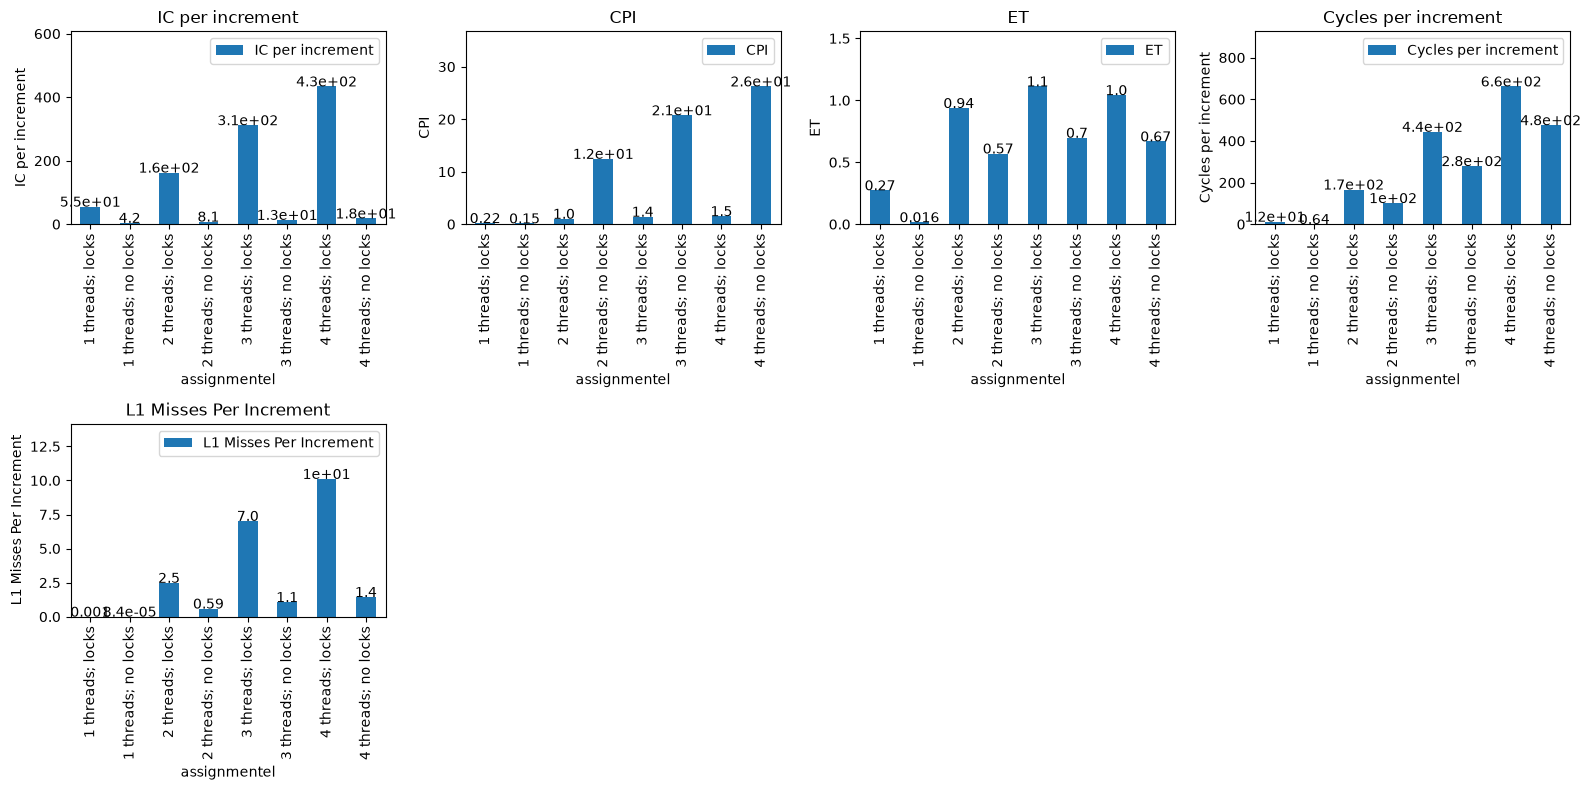

In [18]:
#key data_cell from notebook import * df = render_csv("lock_demo.csv")\ \ndf["assignmentel"] = df["threads"].apply(lambda x: f"{x} threads;" ) + " " +\ \ndf["arg2"].apply(lambda x: "locks" if x else "no locks") df["Total IC"] =\ \ndf["IC"] * df["threads"] df["IC per increment"] =\ \ndf["IC"]/(df["arg1"]/df["threads"]) df["Cycles per increment"] =\ \ndf["Cycles"]/(df["arg1"]/df["threads"]) df["L1 Misses Per Increment"] =\ \ndf["L1_dcache_misses"]/(df["arg1"]/df["threads"]) df["locks"] = df["arg2"]\ \ndisplay_mono(df[["threads", "locks", "IC per increment", "CPI", "ET", "Cycles\ \nper increment", "L1 Misses Per Increment"]]) plotPEBar(df=df,\ \nwhat=[("assignmentel", "IC per increment"), ("assignmentel", "CPI"),\ \n("assignmentel", "ET"),  ("assignmentel", "Cycles per increment"),\ \n("assignmentel", "L1 Misses Per Increment")])

<div class="alert alert-block alert-success"> 

### Question 4 (Correctness)



Answer the questions below:
    
* How much does adding locks slow down the single thread case in terms of cycles per increment? 
    
* How much does adding a second thread slow down each increment in terms of cycles per increment? 
    
* How many cycles does it take to take and release a lock? 
    
For each question, please make sure to include your calculations and clearly state the final answer in this cell. If necessary, you should use LaTeX syntax for equations and formulas. Your answers must base on the experiments above.
</div>

<div class="alert alert-block alert-success">


* How much does adding locks slow down the single thread case in terms of cycles per increment? 
    
* How much does adding a second thread slow down each increment in terms of cycles per increment? 
    
* How many cycles does it take to take and release a lock? 


</div>

,threads,size,arg1,this_core,other_core,arg3,IC,CPI,CT,ET,L1_dcache_miss_rate
0,1,1048576,10000000,0,0,0,1135993957,0.266364,0.375528,0.113630,0.000156
1,1,1048576,10000000,0,1,0,2128856632,1.395762,0.187939,0.558439,0.070495


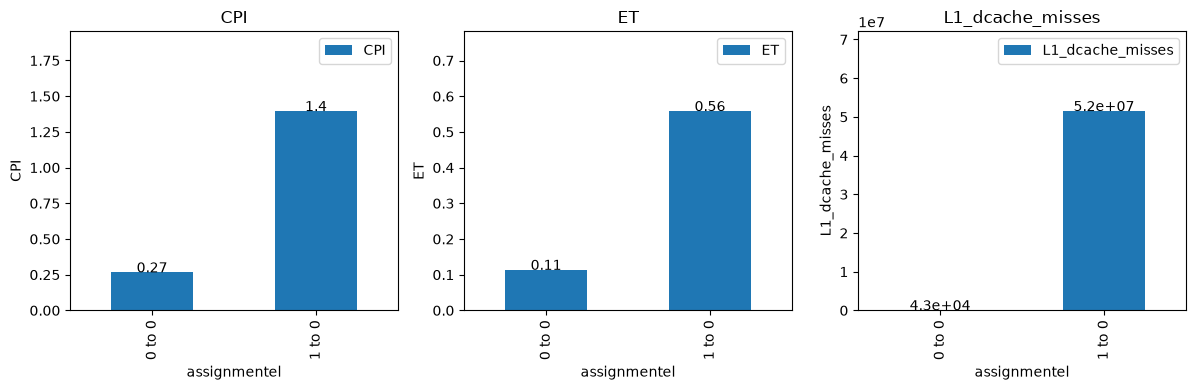

In [20]:
df = render_csv("coherence.csv") df["other_core"] = df["arg2"] df["this_core"] =\ \ndf["arg3"] df["assignmentel"] = df["arg2"].astype(str) + " to " +\ \ndf["arg3"].astype(str)  df["IC per increment"] = df["IC"]/df["arg1"] df["Cycles\ \nper increment"] = df["Cycles"]/df["arg1"] display_mono(df[["threads", "size",\ \n"arg1", "this_core", "other_core", "arg3", "IC", "CPI", "CT", "ET",\ \n"L1_dcache_miss_rate"]]) plotPEBar(df=df,  what=[("assignmentel", "CPI"),\ \n("assignmentel", "ET"), ("assignmentel", "L1_dcache_misses")])

,threads,size,arg1,other_core,arg3,IC,CPI,CT,ET,L1_dcache_miss_rate
0,1,1048576,10000000,0,0,75705361,0.175155,0.417792,0.005540,0.000205
1,1,1048576,10000000,1,0,87987779,13.266928,0.188197,0.219688,0.477582


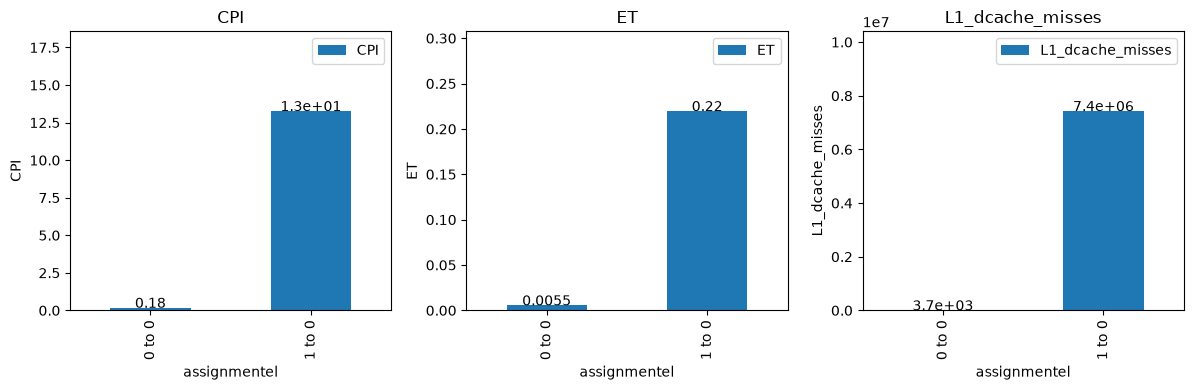

In [22]:
df = render_csv("false_sharing.csv") df["other_core"] = df["arg2"]\ \ndf["this_core"] = df["arg3"] df["assignmentel"] = df["arg2"].astype(str) + " to\ \n" + df["arg3"].astype(str)  df["IC per increment"] = df["IC"]/df["arg1"]\ \ndf["Cycles per increment"] = df["Cycles"]/df["arg1"] display_mono(df[["threads",\ \n"size", "arg1", "other_core", "arg3", "IC", "CPI", "CT", "ET",\ \n"L1_dcache_miss_rate"]]) plotPEBar(df=df,  what=[("assignmentel", "CPI"),\ \n("assignmentel", "ET"), ("assignmentel", "L1_dcache_misses")])

<div class="alert alert-block alert-success">


### Question 5 (Correctness)    



How much difference in performance do you see between running both threads on one core vs. running them on two cores?
    

</div>

<div class="alert alert-block alert-success">   


Please make sure to include your calculations and clearly state the final answer in this cell. If necessary, you should use LaTeX syntax for equations and formulas. Your answers must base on the experiments above.

Answer:
    


</div>

<div class="alert alert-block alert-info">



### Question 6 (Completeness)    



Add a single line to the code above to get the 2x performance improvement we seek. (Hint:  The memory system thinks in cache lines and so should you).
    

</div>

Done code generation...
make: 'fiddle.exe' is up to date.
mkdir -p build/ 
cp *.hpp build/
cp *.h   build/
g++  -DHAVE_LINUX_PERF_EVENT_H -pthread -DHAVE_LINUX_PERF_EVENT_H -I/home/htseng/2026fa/2025fa-cs203-parallelism-starter -g -O3 -fopenmp -lm -pthread -lboost_program_options -L/usr/lib/ -lboost_system -ldl  -rdynamic -fPIC -shared -o build/false_sharing_2.so build/false_sharing_2.cpp

Running sleep 2; ssh -oStrictHostKeyChecking=no htseng@gengar "cd /datahub/htseng/2026fa/2025fa-cs203-parallelism-starter; srun -p datahub ./fiddle.exe -lib ./build/false_sharing_2.so -M 3800 --detail -f false_sharing_2 --arg1 10000000 --arg2 0 1   --arg3 0 -o false_sharing_2.csv"on the cloud for: htseng@ucr.edu

registering function: false_sharing_2
Dynamically registering false_sharing_2
Clamped 16 / 16 CPUs to 3800000 kHz
Clamped 16 / 16 CPUs to 4673823 kHz
Execution started
Execution completed


,threads,size,arg1,other_core,arg3,IC,CPI,CT,ET,L1_dcache_miss_rate
0,1,1048576,10000000,0,0,75705361,0.175155,0.417792,0.005540,0.000205
1,1,1048576,10000000,1,0,87987779,13.266928,0.188197,0.219688,0.477582
2,1,1048576,10000000,0,0,79590183,0.124734,0.577278,0.005731,0.000189
3,1,1048576,10000000,1,0,93422083,10.172415,0.188566,0.179200,0.409104


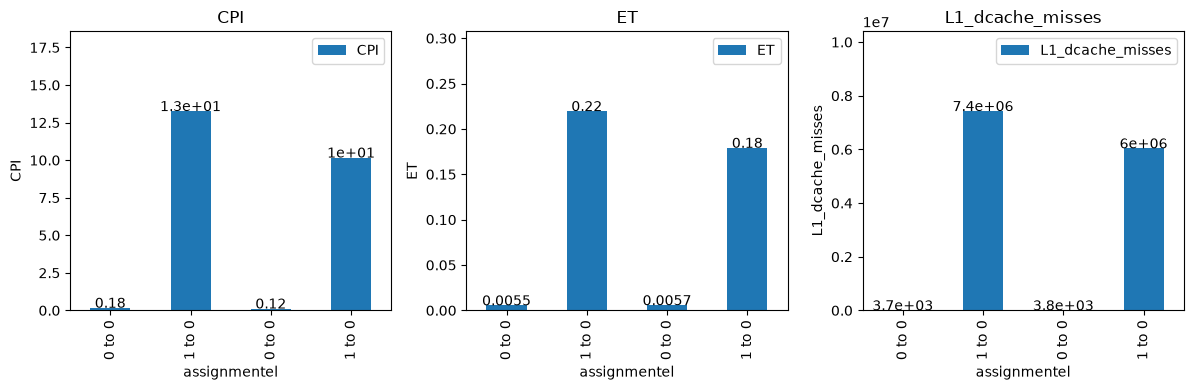

In [23]:
# Please modify the following code in "false_sharing_2" and show result!  t =\ \nfiddle("false_sharing_2.cpp", function="false_sharing_2", opt="-O3", code=r"""\ \n#include"function_map.hpp" #include<cstdint> #include<thread> #include<mutex>\ \n#include"threads.hpp" #include"pthread.h"  volatile int shared = 0; volatile int\ \nnot_shared_0 = 0; volatile int not_shared_1 = 0;  void go_0(uint64_t id,int\ \ncount) {     for(int i= 0; i < count; i++){         not_shared_0++;     } }\ \nvoid go_1(uint64_t id,int count) {     for(int i= 0; i < count; i++){\ \nnot_shared_1++;     } }  extern "C" uint64_t* false_sharing_2(uint64_t\ \nthread_count, uint64_t * data, uint64_t size, uint64_t arg1, uint64_t arg2,\ \nuint64_t arg3) {     shared = 0;     std::thread other (go_0, 1, arg1);\ \nbind_to_core(other, arg2);      bind_to_core(pthread_self(), arg3);     go_1(0,\ \narg1);     other.join();     shared = not_shared_0 + not_shared_1;     return\ \ndata; } FUNCTION(one_array_2arg, false_sharing_2); """)   ! make fiddle.exe;\ \nmake C_OPTS="-O3" build/false_sharing_2.so ! cs203 run "./fiddle.exe -lib\ \n./build/false_sharing_2.so -M 3800 --detail -f false_sharing_2 --arg1 10000000\ \n--arg2 0 1   --arg3 0 -o false_sharing_2.csv"\ \ndf=render_csv(["false_sharing.csv","false_sharing_2.csv"]) df["other_core"] =\ \ndf["arg2"] df["this_core"] = df["arg3"] df["assignmentel"] =\ \ndf["arg2"].astype(str) + " to " + df["arg3"].astype(str)  df["IC per increment"]\ \n= df["IC"]/df["arg1"] df["Cycles per increment"] = df["Cycles"]/df["arg1"]\ \ndisplay_mono(df[["threads", "size", "arg1", "other_core", "arg3", "IC", "CPI",\ \n"CT", "ET", "L1_dcache_miss_rate"]]) plotPEBar(df=df,  what=[("assignmentel",\ \n"CPI"), ("assignmentel", "ET"), ("assignmentel", "L1_dcache_misses")])

<div class="alert alert-block alert-success">


### Question 7 (Correctness)    



Would this code benefit from tiling as a locality optimization?  Why or why not? 


</div>

<div class="alert alert-block alert-success">    


Answer:
        
Please explain in detail to receive credits
</div>

,index,function,threads,size,arg1,arg2,arg3,IC,CPI,ET,L1_dcache_misses,L1_dcache_miss_rate,speedup,Total IC,Total cache misses
0,0,run_unthreaded_histogram,1,10000000,1,1,1,260919777,0.274731,0.027095,942693,0.005323,1.000000,260919777,942693
1,1,run_threaded_histogram,1,10000000,1,1,1,4655846184,0.210533,0.367385,1027079,0.000778,0.073751,4655846184,1027079
2,2,run_threaded_histogram,2,10000000,1,1,1,8347939686,1.324634,2.076384,224211482,0.077327,0.013049,16695879372,448422964
3,3,run_threaded_histogram,3,10000000,1,1,1,11887266411,1.789683,2.671713,415671757,0.090954,0.010141,35661799233,1247015271
4,4,run_threaded_histogram,4,10000000,1,1,1,13132841711,1.957584,2.796013,467440676,0.092024,0.009691,52531366844,1869762704


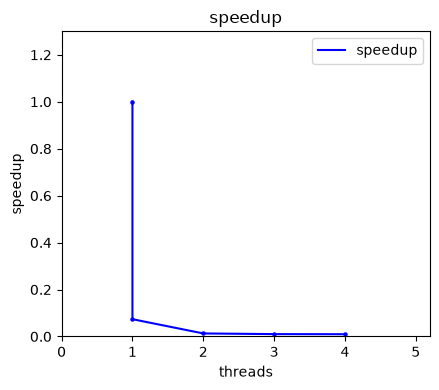

In [30]:
hist_data = render_csv(["histogram_unthreaded.csv", "histogram_threaded.csv"],\ \ncolumns=hist_columns) hist_data["speedup"] =\ \nhist_data.iloc[0]["ET"]/hist_data["ET"] hist_data["Total IC"] =\ \nhist_data["IC"]*hist_data["threads"] hist_data["Total cache misses"] =\ \nhist_data["L1_dcache_misses"]*hist_data["threads"] display(hist_data)\ \nplotPE(df=hist_data, lines=True, what=[("threads", "speedup")])

<div class="alert alert-block alert-success">

    
### Question 8 (Correctness)


How much speedup do you observe with 4 threads? Why?


</div>

<div class="alert alert-block alert-success">    
<div class="answer">
[Please include your calculations in addition to the numerical result. Your answer should come from the experiment above and should include LaTeX forumla if necessary.]

**Speedup:**

**Why:**
    
        
</div>
</div>

<div class="alert alert-block alert-info    "editable": false,">


### Question 9 (Completeness)    



What causes the drop in performance from 1 thread to 2?  How can we fix it?
    
</div>

<div class="alert alert-block alert-info">    

[Be sure to provide good enough guess explaination even though this is a completeness one.]

Answer:
    
    

        
</div>

<div class="alert alert-block alert-warning">


### Question 10 (Challenging) 



What is $x$ for parallel merge sort?  Can you bound speedup for 4 processors, a threshold of 1024, and a total array size of 4096?  If you can't get a precise answer try to estimate or provide an upper bound the value of $x$.
    
(Hint: You should revisit the Amdahl's Law for parallelism part of the material earilier this quarter)
    
</div>


<div class="alert alert-block alert-warning">  


Please observe the above code and explain/justify your estimation.

Answer: 

        
</div>

<div class="alert alert-block alert-info">


### Question 11 (Completeness) 

On Linux, you can use the command `taskset -c list_of_available_cores` to restrict the scheduling policy to allocate your threads on the given set of processors. Can you modified the cell below and find out what's the best list that can deliver the best performance for the runing the histogram program with 4 threads?
    
Remember that we have only 8 logical processors. So the list should only has numbers from 0 to 7.
    
</div>


In [ ]:
# Please run your experiments below using `taskset` command to find out the 4\ \n! cs203 run "taskset -c 0,1,18,19 ./fiddle.exe -lib ./build/histogram.so -M 3800\ \n--detail -f run_private2_histogram --size 10000000 --threads 4 -o\ \nhistogram_taskset.csv" ! cs203 run "taskset -c 0,1,2,3 ./fiddle.exe -lib\ \n./build/histogram.so -M 3800 --detail -f run_private2_histogram --size 10000000\ \n--threads 4 -o histogram_taskset_2.csv"\ \ndisplay_mono(render_csv(["histogram_taskset.csv","histogram_taskset_2.csv"]))

<div class="alert alert-block alert-info">  


Please observe the above experiments that you modified and discuss what's the best combination.

Answer: 

        
</div>